In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import cv2
import os
import zipfile
from sklearn.metrics import confusion_matrix
from tkinter import Tk, filedialog

In [ ]:
with zipfile.ZipFile('archive.zip') as file:
    file.extractall('fer_2013')

In [3]:
path = r'fer_2013\train'
classes = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

x_train = []
y_train = []

for folder in classes:
    print("-"*80)
    print("emotion:\n",folder)
    folder_path = path + '/' + folder #emotions/Emotions/folder
    files = os.listdir(folder_path)
    print("number of files:\n",len(files))
    for file_name in files:
        file_path = folder_path + "/" + file_name
        img = cv2.imread(file_path)
        if img is None:
            continue
        img = cv2.resize(img,(48,48))
        img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
        x_train.append(img)
        y_train.append(folder)
x_train = np.array(x_train, dtype=np.float32) / 255.0



--------------------------------------------------------------------------------
emotion:
 angry
number of files:
 3995
--------------------------------------------------------------------------------
emotion:
 disgust
number of files:
 436
--------------------------------------------------------------------------------
emotion:
 fear
number of files:
 4097
--------------------------------------------------------------------------------
emotion:
 happy
number of files:
 7215
--------------------------------------------------------------------------------
emotion:
 neutral
number of files:
 4965
--------------------------------------------------------------------------------
emotion:
 sad
number of files:
 4830
--------------------------------------------------------------------------------
emotion:
 surprise
number of files:
 3171


In [4]:
path_test = r'fer_2013\test'

x_test = []
y_test = []

for folder in classes:
    print("-"*80)
    print("emotion:\n",folder)
    folder_path = path_test + '/' + folder #emotions/Emotions/folder
    files = os.listdir(folder_path)
    print("number of files:\n",len(files))
    for file_name in files:
        file_path = folder_path + "/" + file_name
        img = cv2.imread(file_path)
        if img is None:
            continue
        img = cv2.resize(img,(48,48))
        img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
        x_test.append(img)
        y_test.append(folder)
x_test = np.array(x_test, dtype=np.float32) / 255.0



--------------------------------------------------------------------------------
emotion:
 angry
number of files:
 958
--------------------------------------------------------------------------------
emotion:
 disgust
number of files:
 111
--------------------------------------------------------------------------------
emotion:
 fear
number of files:
 1024
--------------------------------------------------------------------------------
emotion:
 happy
number of files:
 1774
--------------------------------------------------------------------------------
emotion:
 neutral
number of files:
 1233
--------------------------------------------------------------------------------
emotion:
 sad
number of files:
 1247
--------------------------------------------------------------------------------
emotion:
 surprise
number of files:
 831


In [5]:
one_hot_y_train = pd.get_dummies(y_train)
one_hot_y_test = pd.get_dummies(y_test)

In [6]:
model = Sequential()
model.add(Conv2D(filters=32, kernel_size=(3,3), activation='relu', input_shape=(48,48,1)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(filters=128, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.4))
model.add(Flatten())
model.add(Dense(32, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(7, activation='softmax'))
model.summary()

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        65,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,807 (628.15 KB)

 Trainable params: 160,807 (628.15 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

In [8]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [9]:
es = EarlyStopping(monitor='val_loss', patience=2 , restore_best_weights=True)

In [10]:
hist = model.fit(x_train,one_hot_y_train,epochs=30,batch_size=16,validation_data=(x_test,one_hot_y_test),callbacks=[es])

Epoch 1/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.2972 - loss: 1.7305 - val_accuracy: 0.4087 - val_loss: 1.5133
Epoch 2/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 51s 28ms/step - accuracy: 0.4400 - loss: 1.4419 - val_accuracy: 0.4603 - val_loss: 1.3985
Epoch 3/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 47s 26ms/step - accuracy: 0.4869 - loss: 1.3321 - val_accuracy: 0.5017 - val_loss: 1.2897
Epoch 4/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 48s 27ms/step - accuracy: 0.5171 - loss: 1.2645 - val_accuracy: 0.5276 - val_loss: 1.2295
Epoch 5/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 46s 26ms/step - accuracy: 0.5342 - loss: 1.2220 - val_accuracy: 0.5330 - val_loss: 1.2184
Epoch 6/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 44s 24ms/step - accuracy: 0.5489 - loss: 1.1810 - val_accuracy: 0.5517 - val_loss: 1.1781
Epoch 7/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 47s 26ms/step - accuracy: 0.5638 - loss: 1.1534 - val_accuracy: 0.5507 - val_loss: 1.1615
Epoch 8/30
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 45s 25ms/step - accuracy: 0.5705 -

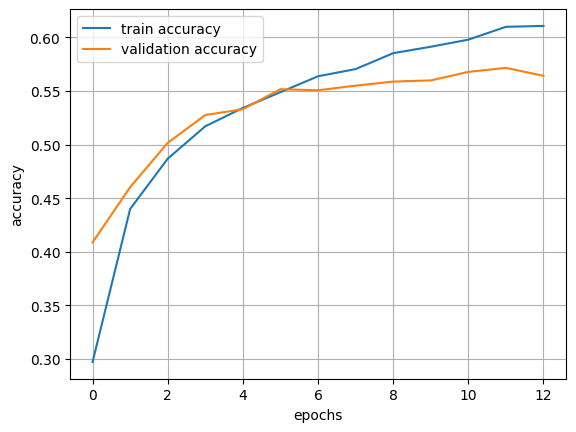

In [11]:
plt.plot(hist.history["accuracy"],label="train accuracy")
plt.plot(hist.history["val_accuracy"],label="validation accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.legend()
plt.grid()
plt.show()    

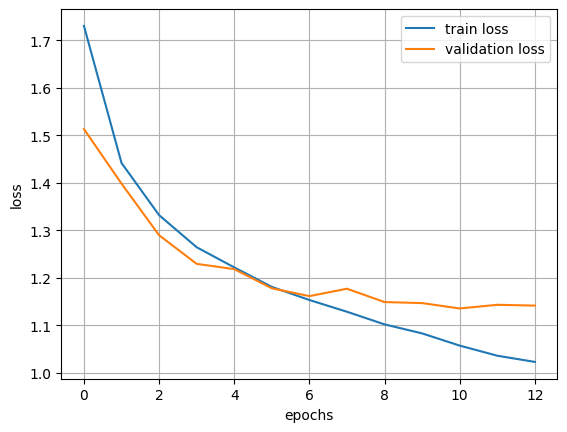

In [12]:
plt.plot(hist.history["loss"],label="train loss")
plt.plot(hist.history["val_loss"],label="validation loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.show()

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


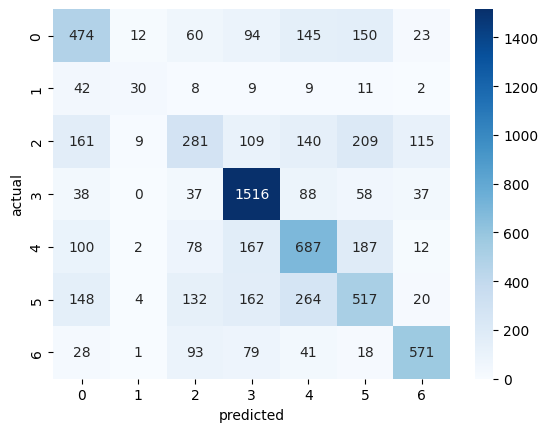

In [13]:
y_pred = np.argmax(model.predict(x_test), axis=1)
y_true = np.argmax(one_hot_y_test, axis=1)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
mood: happy ,confidence: 0.89


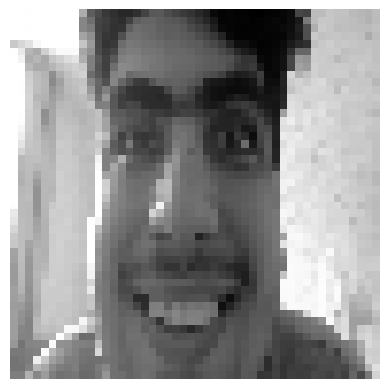

In [15]:
root = Tk()
file = filedialog.askopenfilename(
    filetypes=[("Images", "*.jpg *.jpeg *.png")]
)

if file:
    test = cv2.imread(file)
    test = cv2.resize(test,(48,48))
    test = cv2.cvtColor(test,cv2.COLOR_BGR2GRAY)
    test = np.array(test)/255
    test = test.reshape(1,48,48,1)
    result = model.predict(test)
    mood_num = np.argmax(result)
    
    print('mood:', classes[mood_num], ',confidence:', round(float(np.max(result)), 2))
    plt.imshow(test[0, :, :, 0], cmap='gray')
    plt.axis('off')
    plt.show()